<a href="https://colab.research.google.com/github/gerardagustina/breast-cancer-detection/blob/main/notebooks/02_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breast Cancer Detection — 02. Preprocessing Pipeline
**Goal:** Build a MONAI pipeline: normalisation, data augmentation and batching.

In [ ]:
!pip install -q medmnist monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 11.1 MB/s eta 0:00:00


In [ ]:
import medmnist, torch
from medmnist import BreastMNIST

splits = {s: BreastMNIST(split=s, download=True, size=224) for s in ["train", "val", "test"]}
print({s: len(d) for s, d in splits.items()})
print("GPU disponible:", torch.cuda.is_available())

100%|██████████| 30.9M/30.9M [03:18<00:00, 156kB/s]


{'train': 546, 'val': 78, 'test': 156}
GPU disponible: True


In [ ]:
from monai.data import set_track_meta
set_track_meta(False)   # sin metadatos médicos: trabajamos con tensores simples

from monai.transforms import (Compose, EnsureChannelFirst, ScaleIntensityRange,
                              RandFlip, RandRotate, RandZoom)

base = [
    EnsureChannelFirst(channel_dim="no_channel"),                        # (224,224) → (1,224,224)
    ScaleIntensityRange(a_min=0, a_max=255, b_min=0, b_max=1, clip=True) # 0-255 → 0-1
]

train_tf = Compose(base + [
    RandFlip(prob=0.5, spatial_axis=1),              # volteo horizontal (50% de las veces)
    RandRotate(range_x=0.26, prob=0.5),              # giro de hasta ±15° (0.26 radianes)
    RandZoom(min_zoom=0.9, max_zoom=1.1, prob=0.5),  # zoom de ±10%
])

val_tf = Compose(base)   # val y test: SIN augmentation

print("Transforms listos ✅")

Transforms listos ✅


In [ ]:
from monai.data import ArrayDataset, DataLoader

def make_ds(split, tf):
    d = splits[split]
    return ArrayDataset(img=d.imgs, img_transform=tf, labels=d.labels.ravel())

train_ds = make_ds("train", train_tf)   # con augmentation
val_ds   = make_ds("val",   val_tf)     # sin augmentation
test_ds  = make_ds("test",  val_tf)     # sin augmentation

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

x, y = next(iter(train_loader))
print("Imágenes:", x.shape, "| min:", round(x.min().item(), 2), "| max:", round(x.max().item(), 2))
print("Etiquetas:", y.shape, y[:10])

Imágenes: torch.Size([32, 1, 224, 224]) | min: 0.0 | max: 1.0
Etiquetas: torch.Size([32]) tensor([0, 1, 1, 1, 1, 1, 1, 1, 0, 0], dtype=torch.uint8)


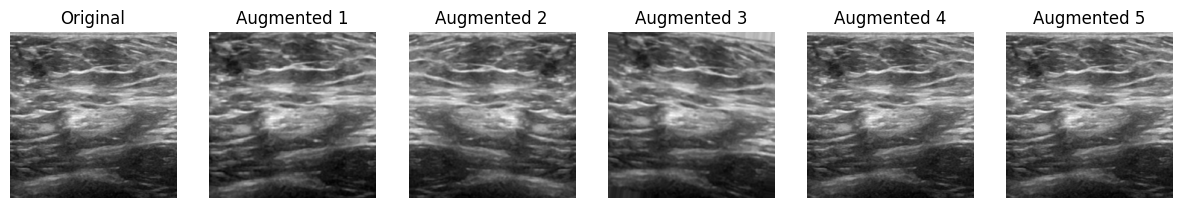

In [ ]:
import matplotlib.pyplot as plt

img = splits["train"].imgs[0]   # una sola imagen de train

fig, ax = plt.subplots(1, 6, figsize=(15, 3))
ax[0].imshow(val_tf(img)[0], cmap="gray"); ax[0].set_title("Original")
for i in range(1, 6):
    ax[i].imshow(train_tf(img)[0], cmap="gray"); ax[i].set_title(f"Augmented {i}")
for a in ax:
    a.axis("off")
plt.show()

## Key decisions
- **Normalisation:** pixel values scaled from [0, 255] to [0, 1].
- **Data augmentation (train only):** horizontal flip, rotation (±15°), zoom (±10%).
  Only anatomically plausible transforms: no vertical flip (skin is always on top in ultrasound).
- **Val/test:** no augmentation, to measure performance on realistic, unmodified images.
- **Batching:** batch size 32, shuffled for training only. Output shape: `(32, 1, 224, 224)`.
- **MONAI MetaTensor tracking disabled:** 2D images without spatial metadata.